import COCO 

In [5]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from tqdm import tqdm #barre de progression.
from pycocotools.coco import COCO

# Charger les splits
with open("../splits/splits_all.json", "r") as f:
    splits = json.load(f)

kb_ids = splits["kb"]
val_ids = splits["val"]
test_ids = splits["test"]
#contient de l'annotation COCO(object+cathegory)
coco_inst = COCO("../data/annotations/instances_train2017.json")

print("KB images:", len(kb_ids))
print("Validation images:", len(val_ids))
print("Test images:", len(test_ids))
print("Available object categories:", len(coco_inst.getCatIds()))

loading annotations into memory...
Done (t=24.43s)
creating index...
index created!
KB images: 10000
Validation images: 100
Test images: 100
Available object categories: 80


annotation images  of our KB

In [6]:
ann_ids = coco_inst.getAnnIds(
    imgIds=kb_ids,
    iscrowd=False
)

annotations = coco_inst.loadAnns(ann_ids)

print("Total object annotations:", len(annotations))

Total object annotations: 72506


calcul the frequancy of cathegoris(number dobject in cat)


In [8]:
#extrait les informations sur les objets à partir des annotations
category_counts = Counter(
    ann["category_id"] for ann in annotations
)
#name cat
categories = coco_inst.loadCats(coco_inst.getCatIds())
#dic_name
cat_names = {
    cat["id"]: cat["name"]
    for cat in categories
}

df_categories = pd.DataFrame([
    {
        "category": cat_names[cat_id],
        "count": count
    }#count de notations 
    for cat_id, count in category_counts.items()
])

df_categories = df_categories.sort_values(
    by="count",
    ascending=False
)

df_top50 = df_categories.head(50)

display(df_top50)

,category,count
6,person,22182
8,car,3619
24,chair,3280
27,bottle,2040
0,cup,1905
11,book,1850
3,dining table,1395
1,bowl,1244
41,traffic light,1113
44,handbag,1051


the 50 Most Frequent Categories

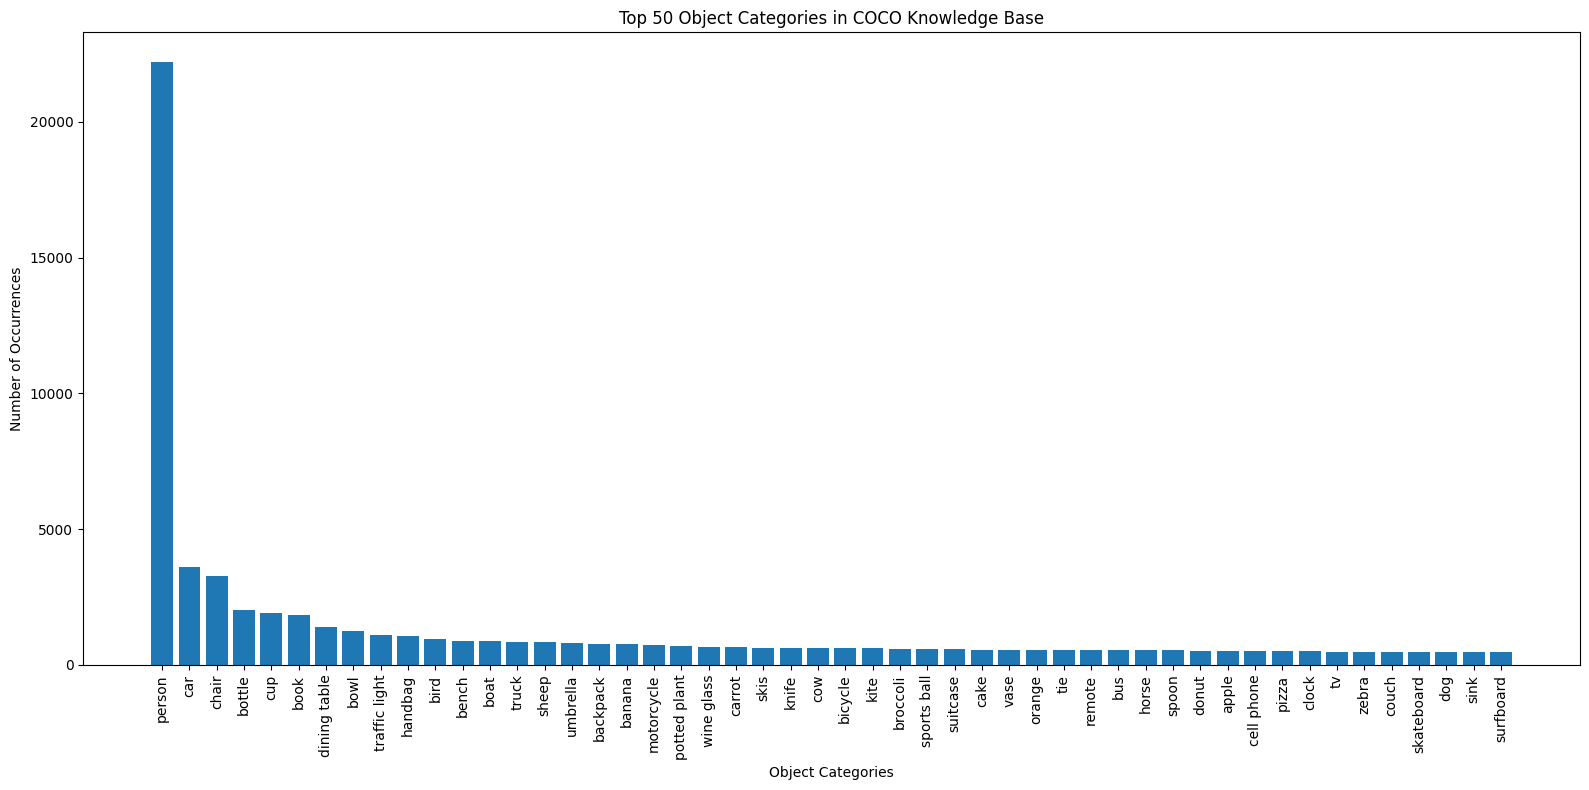

In [10]:
plt.figure(figsize=(16, 8))

plt.bar(
    df_top50["category"],
    df_top50["count"]
)

plt.title("Top 50 Object Categories in COCO Knowledge Base")
plt.xlabel("Object Categories")
plt.ylabel("Number of Occurrences")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Count the Images Containing Each Category

In [9]:
from collections import Counter
category_image_counts = Counter()

for ann in annotations:
    category_image_counts[ann["category_id"]] += 1

# Nombre d'images distinctes par catégorie
category_images = {}

for cat_id in category_counts:
    image_ids = {
        ann["image_id"]
        for ann in annotations
        if ann["category_id"] == cat_id
    }

    category_images[cat_id] = len(image_ids)

df_top50["image_count"] = df_top50["category"].map({
    cat_names[cat_id]: count
    for cat_id, count in category_images.items()
})

display(df_top50.head(10))




,category,count,image_count
6,person,22182,5382
8,car,3619,1041
24,chair,3280,1109
27,bottle,2040,714
0,cup,1905,822
11,book,1850,420
3,dining table,1395,1034
1,bowl,1244,626
41,traffic light,1113,367
44,handbag,1051,599


barchar 

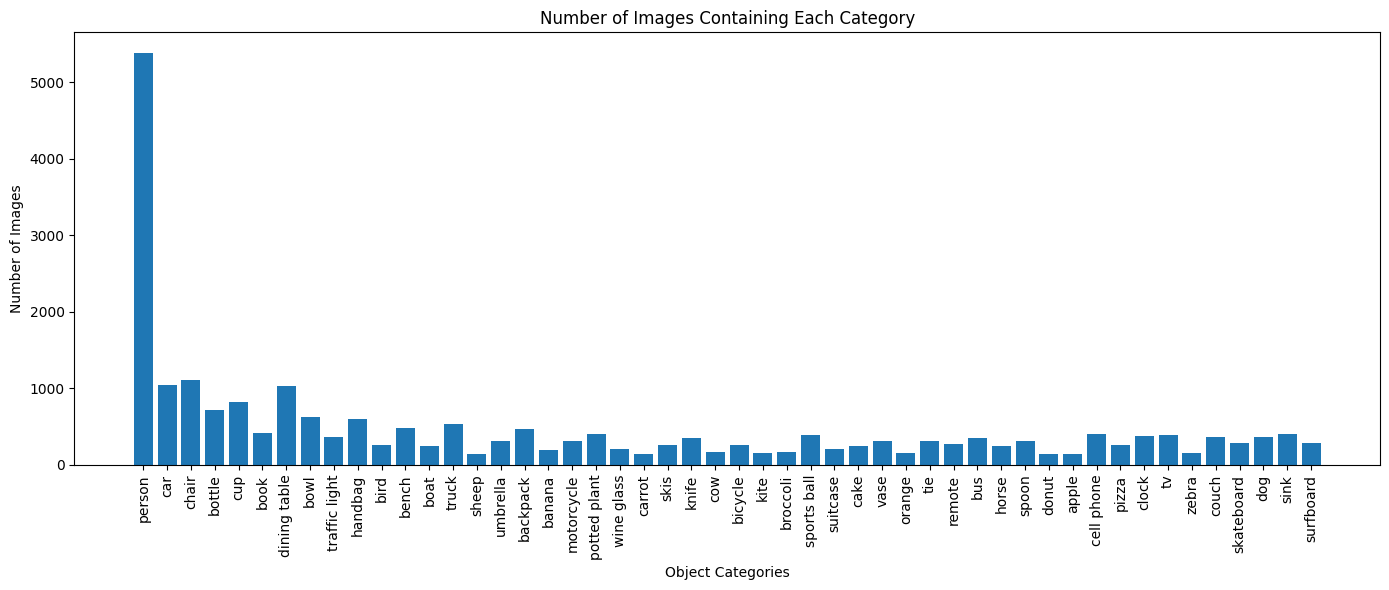

In [12]:
plt.figure(figsize=(14, 6))

plt.bar(
    df_top50["category"],
    df_top50["image_count"]
)

plt.title("Number of Images Containing Each Category")
plt.xlabel("Object Categories")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

Analyze Scene Complexity

Number of Objects per Image

In [10]:
object_counts = Counter( #count annotations per image
    ann["image_id"] for ann in annotations
)

df_objects = pd.DataFrame([
    {
        "image_id": iid,
        "n_objects": object_counts.get(iid, 0)
    }
    for iid in kb_ids
])

display(df_objects.head())

print(df_objects["n_objects"].describe())

,image_id,n_objects
0,101014,5
1,203463,1
2,462398,12
3,550444,15
4,36447,15


count    10000.000000
mean         7.250600
std          7.230811
min          0.000000
25%          2.000000
50%          4.000000
75%         10.000000
max         64.000000
Name: n_objects, dtype: float64


histogram complexité

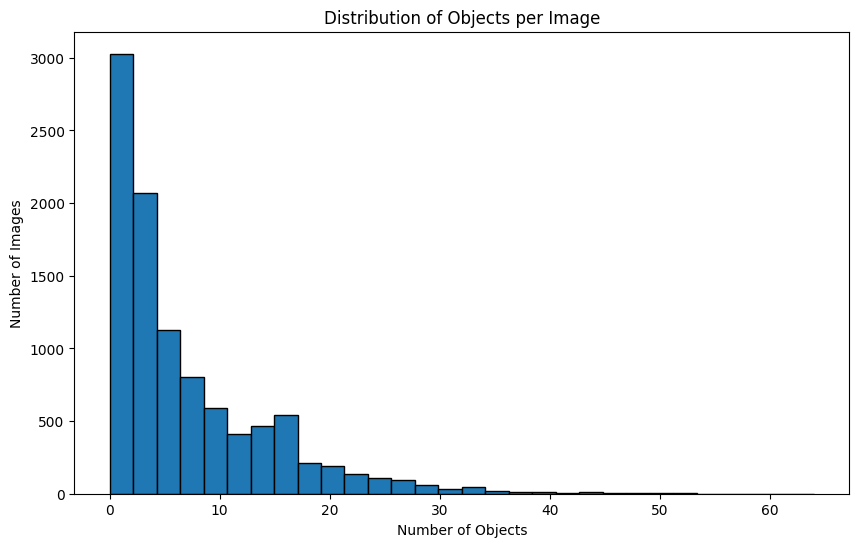

In [11]:
plt.figure(figsize=(10, 6))

plt.hist(
    df_objects["n_objects"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Objects per Image")
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")

plt.show()

Identify Simple and Complex Scenes

In [12]:
simple_scenes = df_objects[
    df_objects["n_objects"] <= 3
]

medium_scenes = df_objects[
    (df_objects["n_objects"] > 3) &
    (df_objects["n_objects"] < 10)
]

complex_scenes = df_objects[
    df_objects["n_objects"] >= 10
]

print("Simple scenes:", len(simple_scenes))
print("Medium scenes:", len(medium_scenes))
print("Complex scenes:", len(complex_scenes))

Simple scenes: 4264
Medium scenes: 3096
Complex scenes: 2640


Object Co-occurrence

In [13]:
from itertools import combinations #categories dobjects they re together 

image_categories = {}

for ann in annotations:
    iid = ann["image_id"]

    if iid not in image_categories:
        image_categories[iid] = set()

    image_categories[iid].add(ann["category_id"])

cooccurrence = Counter()

for cats in image_categories.values():

    for cat1, cat2 in combinations(sorted(cats), 2):
        cooccurrence[(cat1, cat2)] += 1

top_pairs = []

for (cat1, cat2), count in cooccurrence.most_common(20):

    top_pairs.append({
        "object_1": cat_names[cat1],
        "object_2": cat_names[cat2],
        "images_together": count
    })

df_cooccurrence = pd.DataFrame(top_pairs)

display(df_cooccurrence)


,object_1,object_2,images_together
0,person,car,725
1,person,chair,673
2,person,handbag,552
3,person,dining table,514
4,chair,dining table,461
5,person,cup,427
6,person,backpack,425
7,cup,dining table,414
8,person,bottle,379
9,person,bench,376


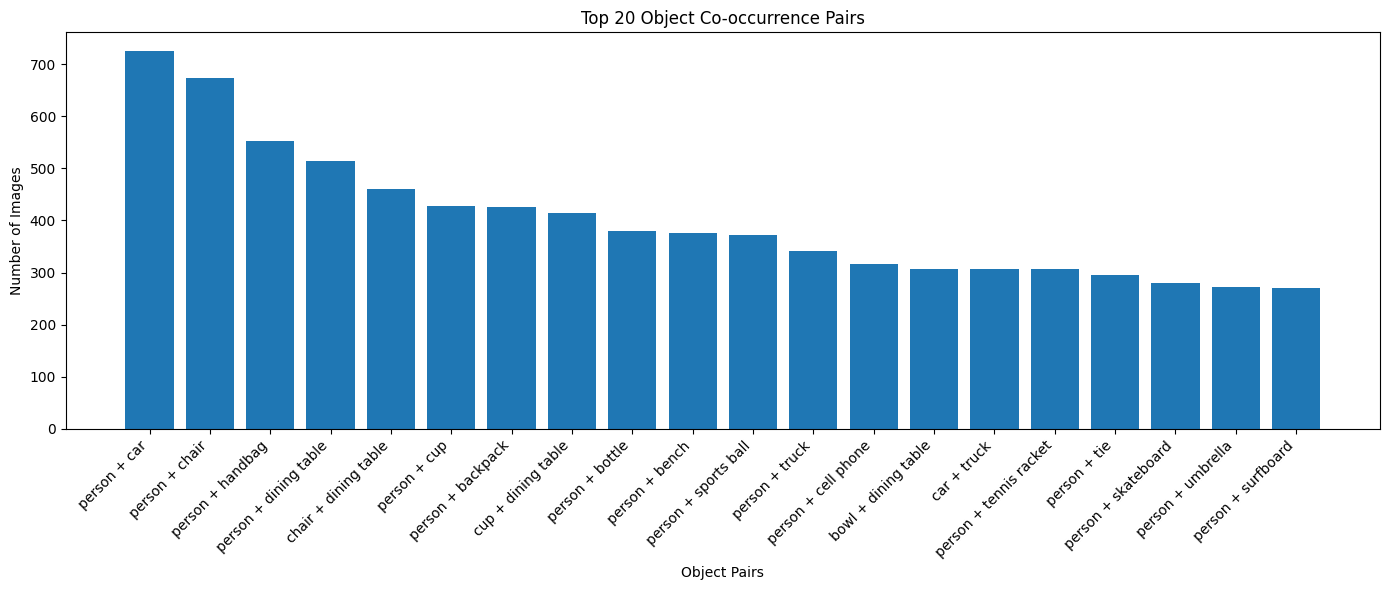

In [14]:

import matplotlib.pyplot as plt

df_plot = df_cooccurrence.copy()

df_plot["object_pair"] = (
    df_plot["object_1"] + " + " + df_plot["object_2"]
)

plt.figure(figsize=(14, 6))

plt.bar(
    df_plot["object_pair"],
    df_plot["images_together"]
)

plt.xlabel("Object Pairs")
plt.ylabel("Number of Images")
plt.title("Top 20 Object Co-occurrence Pairs")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


statistic captions

get the captions

In [ ]:
coco_caps = COCO(
    "../data/annotations/captions_train2017.json"
)

caption_rows = []
#écupères les captions des images
for iid in tqdm(kb_ids):

    anns = coco_caps.loadAnns(
        coco_caps.getAnnIds(imgIds=[iid])
    )

    for ann in anns:
        caption_rows.append({
            "image_id": iid,
            "caption": ann["caption"]
        })

df_captions = pd.DataFrame(caption_rows)

print("Total captions:", len(df_captions))

display(df_captions.head())

loading annotations into memory...
Done (t=0.82s)
creating index...
index created!


100%|██████████| 10000/10000 [00:00<00:00, 69083.55it/s]


Total captions: 50024


,image_id,caption
0,101014,A table filled with some very nice looking food.
1,101014,A black tabletop with two dishes of food and t...
2,101014,A couple of plates filled with different foods.
3,101014,Two plates of food on a table at a restaurant.
4,101014,Two plates of well prepared food sitting next ...


the number of words in caption


In [16]:
df_captions["n_words"] = (
    df_captions["caption"]
    .str.split()
    .str.len()
)

print(df_captions["n_words"].describe())

count    50024.000000
mean        10.464277
std          2.415293
min          7.000000
25%          9.000000
50%         10.000000
75%         11.000000
max         49.000000
Name: n_words, dtype: float64


Caption Length Distribution

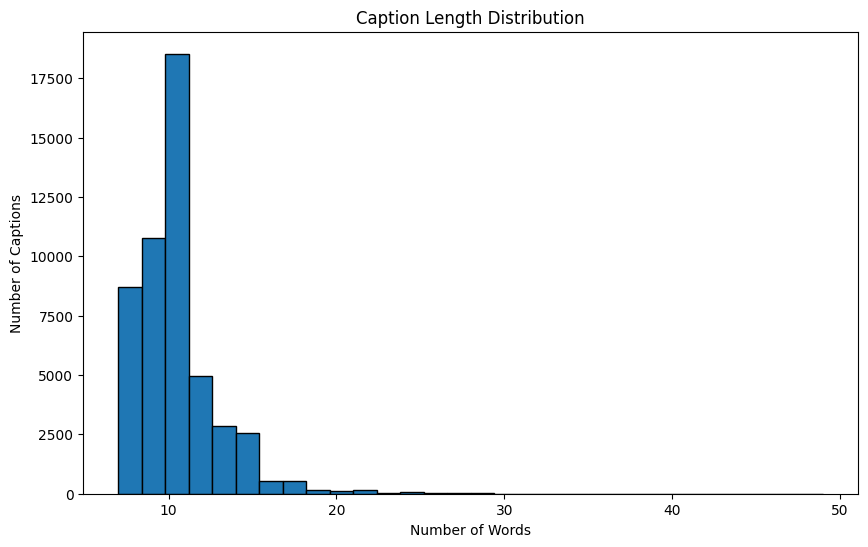

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(
    df_captions["n_words"],
    bins=30,
    edgecolor="black"
)

plt.title("Caption Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Captions")

plt.show()

Calculate Vocabulary Size

In [18]:
import re

all_words = []

for caption in df_captions["caption"]:

    words = re.findall(
        r"\b[a-zA-Z]+\b",
        caption.lower()
    )

    all_words.extend(words)

vocabulary = set(all_words)

print("Total word occurrences:", len(all_words))
print("Vocabulary size:", len(vocabulary))

Total word occurrences: 524313
Vocabulary size: 9576


Most Frequent Words

,word,frequency
0,a,82744
1,on,18247
2,of,17319
3,the,16751
4,in,15359
5,with,13113
6,and,12107
7,is,8369
8,man,6128
9,to,5660


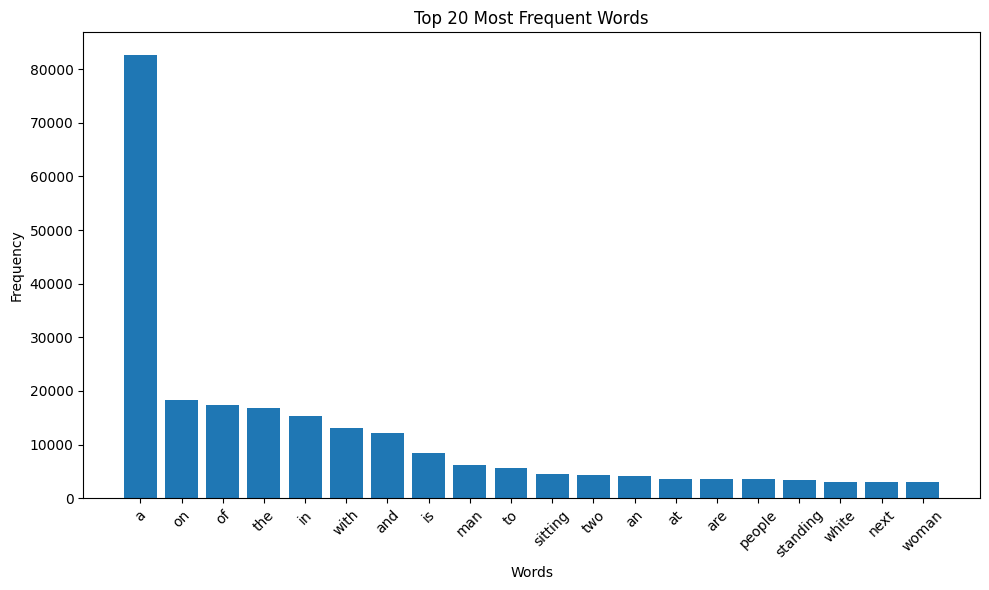

In [19]:
word_counts = Counter(all_words)

df_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["word", "frequency"]
)

display(df_words)

plt.figure(figsize=(10, 6))

plt.bar(
    df_words["word"],
    df_words["frequency"]
)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

colors of images

In [19]:
import random
from PIL import Image

sample_ids = random.Random(42).sample(kb_ids, 500)

color_values = []

for iid in tqdm(sample_ids):

    info = coco_inst.loadImgs([iid])[0]
    path = f"../data/images/train/{info['file_name']}"
#chercher la couleur dominante de l'image
    with Image.open(path) as im:

        im = im.convert("RGB")
        im.thumbnail((100, 100))

        colors = im.getcolors(10000)

        if colors:
            dominant = max(colors, key=lambda x: x[0])[1]
            color_values.append(dominant)

print("Images analyzed:", len(color_values))



100%|██████████| 500/500 [00:04<00:00, 122.03it/s]

Images analyzed: 500


In [20]:

from collections import Counter
import pandas as pd

color_counts = Counter(color_values)

df_colors = pd.DataFrame(
    [
        {
            "RGB Color": str(color),
            "Frequency": count
        }
        for color, count in color_counts.most_common(10)
    ]
)

display(df_colors)


,RGB Color,Frequency
0,"(255, 255, 255)",88
1,"(0, 0, 0)",52
2,"(1, 1, 1)",8
3,"(254, 254, 254)",6
4,"(253, 253, 253)",5
5,"(2, 2, 2)",4
6,"(9, 9, 9)",4
7,"(252, 252, 252)",3
8,"(4, 4, 4)",2
9,"(5, 5, 5)",2


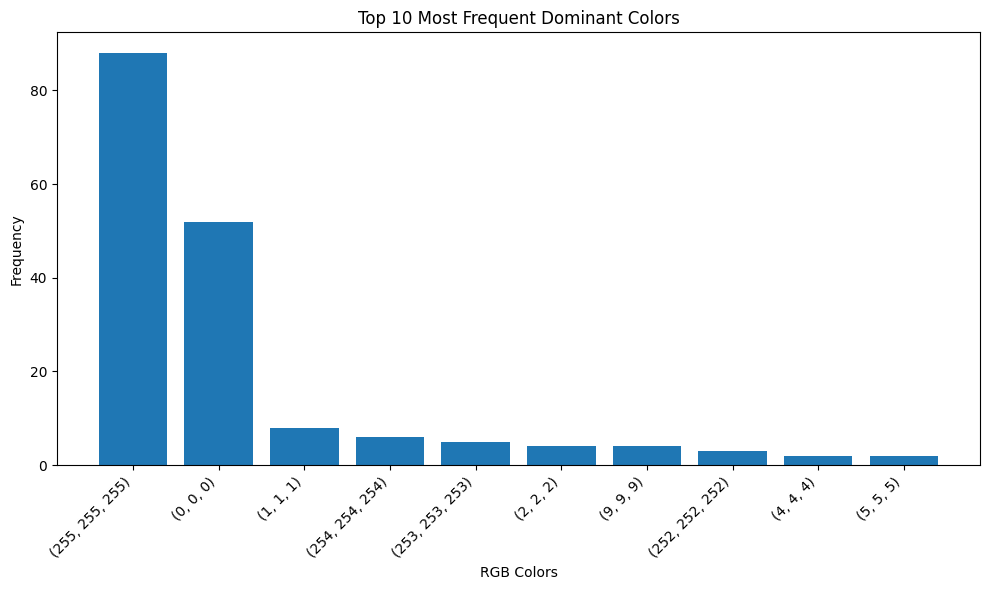

In [21]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    df_colors["RGB Color"],
    df_colors["Frequency"]
)

plt.title("Top 10 Most Frequent Dominant Colors")
plt.xlabel("RGB Colors")
plt.ylabel("Frequency")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [23]:
os.makedirs("data/processed/exploration", exist_ok=True)

df_top50.to_csv(
    "data/processed/exploration/top50_categories.csv",
    index=False
)

df_objects.to_csv(
    "data/processed/exploration/scene_complexity.csv",
    index=False
)

df_cooccurrence.to_csv(
    "data/processed/exploration/object_cooccurrence.csv",
    index=False
)

df_captions.to_csv(
    "data/processed/exploration/caption_statistics.csv",
    index=False
)

df_words.to_csv(
    "data/processed/exploration/top_words.csv",
    index=False
)

print("Exploration results saved successfully.")

Exploration results saved successfully.


In [24]:
import os

folder = "../data/processed/exploration"

print(os.listdir(folder))

FileNotFoundError: [WinError 3] Le chemin d’accès spécifié est introuvable: '../data/processed/exploration'

In [25]:
import os

print(os.listdir("../data"))

['annotations', 'images', 'processed']


In [26]:
print(os.listdir("../data/processed"))

['captions.csv', 'test']


In [27]:
import os

folder = "../data/processed/exploration"
os.makedirs(folder, exist_ok=True)

df_top50.to_csv(f"{folder}/top50_categories.csv", index=False)
df_objects.to_csv(f"{folder}/scene_complexity.csv", index=False)
df_cooccurrence.to_csv(f"{folder}/object_cooccurrence.csv", index=False)
df_captions.to_csv(f"{folder}/caption_statistics.csv", index=False)
df_words.to_csv(f"{folder}/top_words.csv", index=False)

print("Fichiers sauvegardés :")
print(os.listdir(folder))

Fichiers sauvegardés :
['caption_statistics.csv', 'object_cooccurrence.csv', 'scene_complexity.csv', 'top50_categories.csv', 'top_words.csv']
